# Phân đoạn khách hàng bằng K-means

Mỗi dòng là một khách hàng. Tám biến RFM và hành vi từ TV1 đã được biến đổi và chuẩn hóa. K-means đo khoảng cách Euclidean trong không gian này và biểu diễn mỗi cụm bằng tâm trung bình.

WCSS: Tổng bình phương khoảng cách từ mỗi điểm dữ liệu tới tâm cụm của nó.

Với $k$ cụm $C_1,\ldots,C_k$ và các tâm $\mu_1,\ldots,\mu_k$, mục tiêu là giảm tổng bình phương khoảng cách nội cụm.

$$
\mathrm{WCSS}=\sum_{j=1}^{k}\sum_{x_i\in C_j}\lVert x_i-\mu_j\rVert_2^2.
$$

Thuật toán Lloyd:
Đầu tiên gán mỗi điểm vào tâm cụm gần nhất, sau đó cập nhật tâm cụm mới đến trọng tâm của các điểm trong nhóm đó.

In [1]:
import sys
from pathlib import Path

working_dir = Path.cwd()
for directory in (working_dir, *working_dir.parents):
    if (directory / "clustering" / "models.py").is_file():
        if str(directory) not in sys.path:
            sys.path.insert(0, str(directory))
        break
else:
    raise RuntimeError("Hãy mở notebook với kernel chạy trong thư mục repo.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples

from clustering.models import (
    MODELS_DIR,
    RANDOM_STATE,
    RAW_FEATURES_PATH,
    RESULTS_DIR,
    cross_validate_kmeans,
    evaluate_clustering,
    fit_kmeans,
    load_customer_features,
    load_scaled_data,
    run_grid_search,
    save_cluster_labels,
    save_model,
    save_tuning_results,
)

REVIEW_K = None  # Có thể điền k sau khi xem biểu đồ, bảng điểm và hồ sơ cụm.

customer_ids, X = load_scaled_data()
results_dir, models_dir = RESULTS_DIR, MODELS_DIR
# raw để test 5-fold
raw_features = load_customer_features(RAW_FEATURES_PATH).loc[customer_ids.tolist()]

X.head()

Đã đọc 5,852 khách hàng từ data/processed/X_scaled.csv


,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,AvgBasketSize,Tenure,CancelRate
0,0.459111,0.000000,2.389324,5.370007,-0.346066,4.913311,0.332394,1.25
1,-1.204557,0.584963,0.927628,0.940491,0.615983,0.842417,-0.352113,0.00
2,-0.087234,0.292481,0.350623,0.209306,-0.369856,1.207368,-0.256338,0.00
3,-0.596525,0.000000,0.773214,1.757777,0.666367,1.206533,0.169014,1.25
4,0.441371,-0.500000,-0.565206,0.068318,-0.603781,0.226287,-0.616901,0.00


## Đối chiếu Elbow và các tiêu chí chọn $k$

Chạy $k$ từ 2 đến 10 và đối chiếu cùng lúc nhiều tiêu chí thay vì chỉ nhìn một chỉ số:

- Elbow (WCSS / `inertia`): tìm điểm gãy (`elbow_k`) nơi WCSS bắt đầu giảm chậm. Điểm gãy được ước lượng bằng cách đưa hai trục về đoạn $[0, 1]$ rồi lấy vị trí lệch xa nhất so với dây nối hai đầu ($k=2$ và $k=10$).
- Silhouette Score ($[-1, 1]$, cao hơn là tốt hơn): $s_i = (b_i - a_i) / \max(a_i, b_i)$, so sánh khoảng cách trung bình trong cụm ($a_i$) với cụm gần nhất khác ($b_i$).
- Davies-Bouldin Index ($\ge 0$, nhỏ hơn là tốt hơn): tỷ lệ độ phân tán nội cụm trên khoảng cách giữa các tâm cụm.
- Calinski-Harabasz Index (cao hơn là tốt hơn): tỷ lệ phương sai giữa các cụm trên phương sai nội cụm.
- Kích thước cụm (`min_cluster_size`, `max_cluster_size`): tránh các lát cắt tách vài điểm cực trị thành cụm quá nhỏ.

Vì Silhouette thường cao nhất ở $k=2$ (quá thô cho phân khúc marketing), mặc định chọn $k$ có Silhouette tốt nhất quanh vùng điểm gãy (`elbow_k +/- 1`) và vẫn in toàn bộ bảng để đối chiếu với mục tiêu 4 nhóm của đề (có thể chỉnh tay bằng `REVIEW_K`).

In [2]:
K_VALUES = list(range(2, 11))

tuning = run_grid_search(
    X,
    model_builder=lambda n_clusters: KMeans(
        n_clusters=n_clusters, init="k-means++", n_init=10, random_state=RANDOM_STATE
    ),
    param_grid={"n_clusters": K_VALUES},
).set_index("n_clusters")

progress = np.linspace(0, 1, len(tuning))
inertia = tuning["inertia"]
normalized_drop = (inertia.iloc[0] - inertia) / max(
    inertia.iloc[0] - inertia.iloc[-1], np.finfo(float).eps
)
elbow_k = int((normalized_drop - progress).idxmax())
silhouette_k = int(tuning["silhouette"].idxmax())
near_elbow = tuning.loc[elbow_k - 1 : elbow_k + 1, "silhouette"]
best_k = int(near_elbow.idxmax()) if REVIEW_K is None else REVIEW_K
if best_k not in K_VALUES:
    raise ValueError(f"REVIEW_K nằm ngoài dải thử {K_VALUES}.")

tuning["elbow_candidate"] = tuning.index == elbow_k
tuning["selected"] = tuning.index == best_k
print(f"Elbow gợi ý k={elbow_k}, Silhouette cao nhất ở k={silhouette_k}, xuất thử k={best_k}.")
tuning[["inertia", "silhouette", "davies_bouldin", "calinski_harabasz",
        "min_cluster_size", "max_cluster_size", "selected"]]

Elbow gợi ý k=5, Silhouette cao nhất ở k=2, xuất thử k=4.


,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size,selected
n_clusters,,,,,,,
2,17544.637905,0.259080,1.409198,2512.697508,2795,3057,False
3,15168.347157,0.189623,1.634050,1911.095833,1398,2633,False
4,13116.347407,0.217712,1.401104,1778.083879,938,1982,True
5,11781.060315,0.206804,1.365501,1650.142865,841,1462,False
6,10876.798257,0.191554,1.360856,1526.820871,732,1471,False
7,10096.680483,0.191380,1.351466,1445.700067,597,1133,False
8,9519.653064,0.190309,1.360000,1364.654632,257,1030,False
9,9035.425640,0.190687,1.384074,1296.990625,222,1020,False
10,8587.162145,0.188722,1.383558,1246.740388,197,961,False


## Xem hình dạng và kích thước cụm

Hàng trên vẽ đường Elbow và Silhouette trung bình theo $k$, đường nét đứt màu cam đánh dấu $k$ đang chọn.

Hàng dưới là Silhouette plot cho từng cụm (`C0, C1, ...`):
- Chiều cao mỗi dải màu thể hiện số khách trong cụm. Các dải dày tương đương nhau cho thấy cụm phân bố đều.
- Trục ngang là giá trị $s_i$ của từng khách: phần bên phải `0.0` là khách bám tốt vào cụm hiện tại, phần âm bên trái `0.0` là khách nằm ở vùng chồng lấn.
- Đường nét đứt màu đỏ là Silhouette trung bình toàn tập; phân cụm tốt khi các cụm đều vượt đường này và đuôi âm nhỏ.

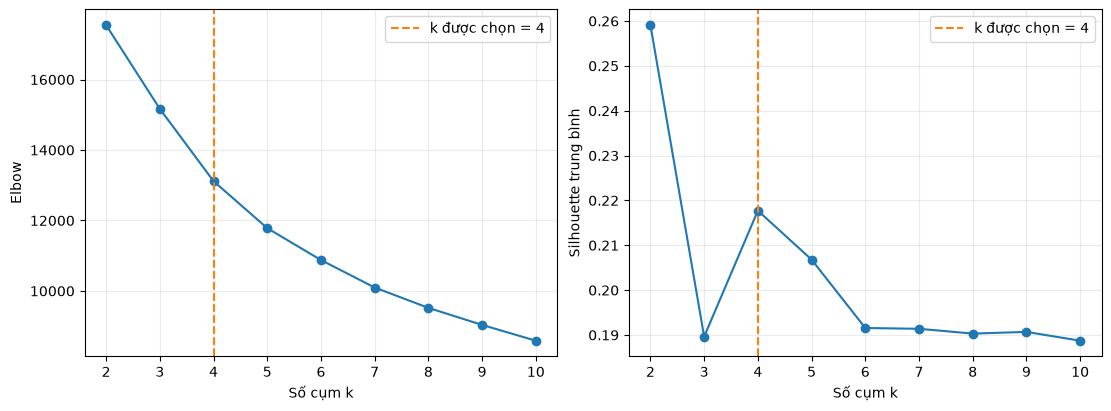

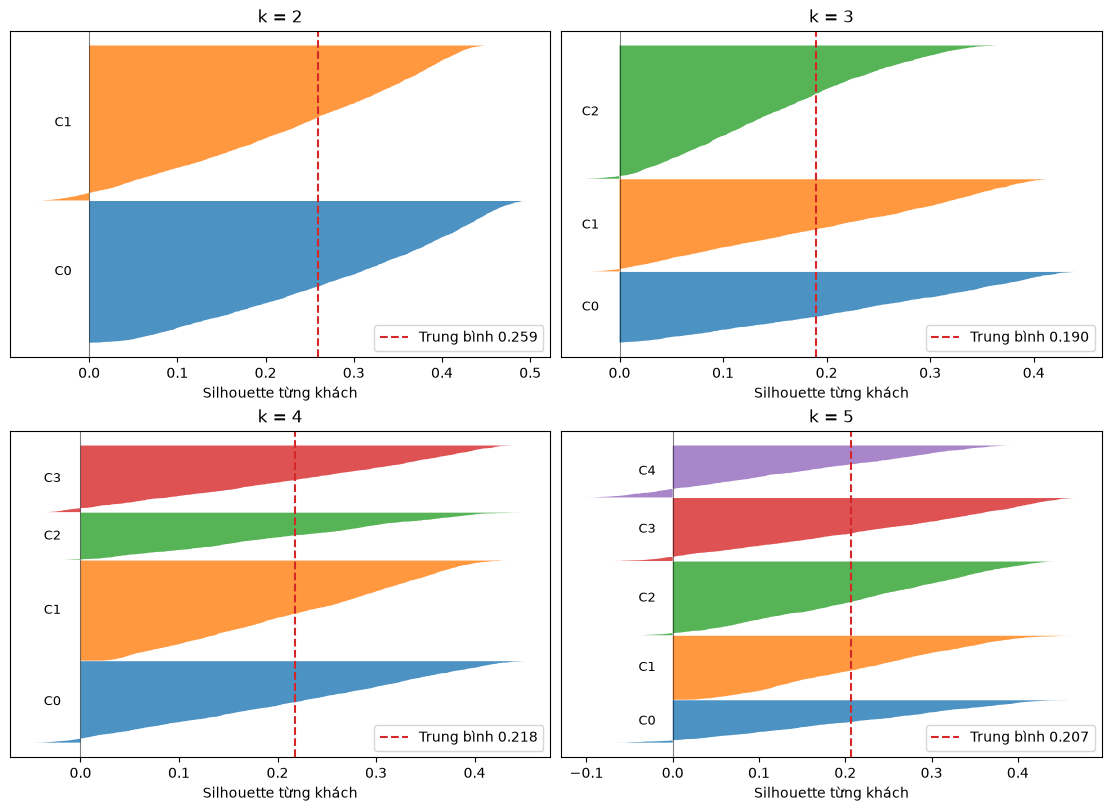

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, metric, title in zip(axes, ["inertia", "silhouette"], ["Elbow", "Silhouette trung bình"]):
    ax.plot(tuning.index, tuning[metric], marker="o")
    ax.axvline(best_k, color="tab:orange", linestyle="--", label=f"k được chọn = {best_k}")
    ax.set(xlabel="Số cụm k", ylabel=title, xticks=K_VALUES)
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

candidates = sorted({2, 3, 4, 5, elbow_k, silhouette_k, best_k})
ncols = 2
nrows = int(np.ceil(len(candidates) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 4 * nrows), squeeze=False, constrained_layout=True)
for ax, k in zip(axes.flat, candidates):
    _, labels = fit_kmeans(X, n_clusters=k)
    scores = silhouette_samples(X, labels)
    start = 0
    for label in np.unique(labels):
        values = np.sort(scores[labels == label])
        end = start + len(values)
        ax.fill_betweenx(np.arange(start, end), 0, values, alpha=0.8)
        ax.text(-0.02, (start + end) / 2, f"C{label}", va="center", ha="right", fontsize=9)
        start = end + 10
    ax.axvline(scores.mean(), color="tab:red", linestyle="--", label=f"Trung bình {scores.mean():.3f}")
    ax.axvline(0, color="black", linewidth=0.8, alpha=0.5)
    ax.set(title=f"k = {k}", xlabel="Silhouette từng khách", yticks=[])
    ax.legend(loc="lower right")
for ax in axes.flat[len(candidates):]:
    ax.set_visible(False)
plt.show()

## Kiểm tra ngoài mẫu bằng 5-fold

Dùng 5-fold cross-validation để xem các tâm cụm học được có ổn định khi gán cụm cho khách hàng mới hay không.

Với mỗi fold (4 phần train, 1 phần test):
1. Từ bảng đặc trưng gốc (`raw_features`), áp dụng `log1p` và fit `RobustScaler` riêng trên tập train rồi biến đổi tập test để tránh rò rỉ dữ liệu.
2. Fit K-means trên tập train lấy $k$ tâm cụm $\hat{\mu}_1, \ldots, \hat{\mu}_k$.
3. Tính WCSS trung bình mỗi khách trên tập test $T$:

$$
E_{\mathrm{test}}(k)=\frac{1}{|T|}\sum_{x_i\in T}\min_{1\le j\le k}\lVert x_i-\hat{\mu}_j\rVert_2^2.
$$

`cv_test_wcss_mean` đo khoảng cách bình phương trung bình từ khách mới tới tâm gần nhất (cần nhìn tốc độ giảm giống Elbow), còn `cv_test_wcss_std` đo độ ổn định giữa 5 fold.

In [4]:
cv_scores = cross_validate_kmeans(raw_features, K_VALUES)
cv_summary = cv_scores.groupby("n_clusters")["test_wcss_per_customer"].agg(
    cv_test_wcss_mean="mean", cv_test_wcss_std="std"
)
tuning = tuning.join(cv_summary)
display(cv_summary.round(4))

,cv_test_wcss_mean,cv_test_wcss_std
n_clusters,,
2,3.0025,0.1348
3,2.5995,0.1087
4,2.2518,0.0896
5,2.0244,0.0849
6,1.8825,0.0774
7,1.7389,0.0751
8,1.6412,0.0686
9,1.5646,0.0606
10,1.4799,0.0614


## Kiểm tra khởi tạo và xuất kết quả

Tại $k$ đã chọn, thử lại với `k-means++` và `random` cùng nhiều mức `n_init` để kiểm tra tính ổn định của kết quả. Độ giống nhau giữa các lần chạy được đo bằng ARI (Adjusted Rand Index, trong $[-1, 1]$), không bị ảnh hưởng khi thứ tự mã cụm thay đổi (`1.0` là trùng khớp hoàn toàn).

Cấu hình lưu ra dùng `init="k-means++"`, `n_init=10`. Đầu ra gồm `tuning_kmeans.csv`, cột `kmeans` trong `labels.csv` (cho TV3) và `kmeans.joblib` (dùng kèm `scaler.joblib` cho TV4).

In [5]:
final_model, final_labels = fit_kmeans(X, n_clusters=best_k)
stability = [{
    "init": "k-means++",
    "n_init": 10,
    "inertia": final_model.inertia_,
    "ari_vs_final": 1.0,
    "is_baseline": True,
}]
for init, n_init in [("k-means++", 5), ("k-means++", 20), ("random", 10)]:
    model, labels = fit_kmeans(X, n_clusters=best_k, init=init, n_init=n_init)
    stability.append({
        "init": init,
        "n_init": n_init,
        "inertia": model.inertia_,
        "ari_vs_final": adjusted_rand_score(final_labels, labels),
        "is_baseline": False,
    })

display(pd.DataFrame(stability).round(4))
display(pd.Series(final_labels, name="Số khách mỗi cụm của final model initialization").value_counts().sort_index())
save_tuning_results(tuning.reset_index(), "tuning_kmeans.csv", results_dir)
save_cluster_labels(customer_ids, "kmeans", final_labels, results_dir / "labels.csv")
_ = save_model(final_model, models_dir=models_dir)

,init,n_init,inertia,ari_vs_final,is_baseline
0,k-means++,10,13116.3474,1.0000,True
1,k-means++,5,13116.3474,1.0000,False
2,k-means++,20,13116.3474,1.0000,False
3,random,10,13116.3536,0.9988,False


Số khách mỗi cụm của final model initialization
0    1613
1    1982
2     938
3    1319
Name: count, dtype: int64

[SAVED] Đã lưu bảng tinh chỉnh -> clustering/results/tuning_kmeans.csv
[SAVED] Đã cập nhật cột 'kmeans' -> clustering/results/labels.csv
[SAVED] Đã lưu model -> models/kmeans.joblib


## Đối chứng với RFM ba biến

Chạy thêm một mô hình chỉ dùng 3 biến RFM cơ bản (`Recency`, `Frequency`, `Monetary`) với cùng $k$ để kiểm tra tác động của 5 biến hành vi bổ sung (`AvgOrderValue`, `UniqueProducts`, `AvgBasketSize`, `Tenure`, `CancelRate`).

Khi đọc bảng kết quả, chỉ so sánh trong cùng một cột (cùng không gian đo khoảng cách) chứ không so chéo giữa cột 3 biến và cột 8 biến, vì không gian ít chiều luôn có xu hướng cho Silhouette cao hơn. Nếu mô hình 8 biến cao hơn rõ trên cột `Silhouette trên 8 biến`, nghĩa là các biến hành vi thực sự tạo thêm cấu trúc phân tách. Nhãn và model bàn giao vẫn dùng cấu hình 8 biến.

In [6]:
X_rfm = X[["Recency", "Frequency", "Monetary"]]
_, rfm_labels = fit_kmeans(X_rfm, n_clusters=best_k)

comparison = []
for name, labels in [("RFM (3 biến)", rfm_labels), ("RFM và 5 biến hành vi (8 biến)", final_labels)]:
    comparison.append({
        "Mô hình": name,
        "Silhouette trên 3 biến": evaluate_clustering(X_rfm, labels)["silhouette"],
        "Silhouette trên 8 biến": evaluate_clustering(X, labels)["silhouette"],
    })
display(pd.DataFrame(comparison).set_index("Mô hình").round(4))


,Silhouette trên 3 biến,Silhouette trên 8 biến
Mô hình,,
RFM (3 biến),0.3608,0.1215
RFM và 5 biến hành vi (8 biến),0.1035,0.2177
